# Figure 4: Reach and concentration

Rebuild the reach ratios for ImageJ/Fiji, the other analysis packages, and microscope-control programs. Panel a counts each paper once per group, so a paper mentioning several analysis packages contributes to the group count once. Panel b gives ImageJ/Fiji's share of analysis-package mentions with and without microscope-control software. See `MANUSCRIPT/01_MAIN.md`, Results, A full-text census of 30 packages, Figure 4 caption, and Methods, Denominators.


In [1]:
from pathlib import Path
import sys
from tempfile import TemporaryDirectory

import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib import image as mpimg
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
REPO_ROOT = next((p for p in (cwd, *cwd.parents) if (p / 'scripts' / 'census' / '_registry.py').is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError('Could not locate scripts/census/_registry.py from the notebook working directory')
SCRIPTS_DIR = REPO_ROOT / 'scripts'
FIGURES_DIR = SCRIPTS_DIR / 'census' / 'figures'
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from census._registry import build_boolean_query, load_registry
from census.figures import fig4_reach as figure
from census.figures import style as fs

reg = load_registry()
def inspect_processed(name, columns=None):
    frame = fs.load(name)
    print(f'{name}: shape={frame.shape}')
    display((frame if columns is None else frame[columns]).head())
    return frame

## Registry and query construction

The shared query context restricts the registry aliases to microscopy papers with indexed full text. The aggregate flag includes 28 packages. The analysis group contains 22 packages and excludes six microscope-control programs, MATLAB and Jupyter notebooks.


In [2]:
registry_table = pd.DataFrame([
    {'tool_id': tool.id, 'name': tool.name, 'category': tool.category, 'scope': tool.scope,
     'in_aggregate': tool.in_aggregate, 'aliases': ' | '.join(tool.aliases),
     'query': build_boolean_query(tool, reg.context_query)}
    for tool in reg.tools
])
print(f'{len(reg.tools)} packages; years {reg.year_start}-{reg.year_end}')
print(f'Shared context: {reg.context_query}')
print(f'Registry table shape: {registry_table.shape}')
display(registry_table.drop(columns='query').head(8))
display(registry_table.loc[registry_table.tool_id.isin(['imagej', 'zen', 'cellpose']), ['tool_id', 'aliases', 'query']])

30 packages; years 2010-2025
Shared context: (microscopy OR microscope) AND HAS_FT:Y
Registry table shape: (30, 7)


,tool_id,name,category,scope,in_aggregate,aliases
0,jupyter,Jupyter notebooks,notebook,core,False,Jupyter | Jupyter notebook | IPython notebook
1,imagej,ImageJ / Fiji,general-platform,core,True,ImageJ | ImageJ2 | Fiji | FIJI
2,napari,napari,general-platform,core,True,napari
3,cellprofiler,CellProfiler,general-platform,core,True,CellProfiler
4,qupath,QuPath,general-platform,core,True,QuPath
5,icy,Icy,general-platform,core,True,Icy bioimage | Icy software | de Chaumont Icy
6,ilastik,ilastik,general-platform,core,True,ilastik
7,knime,KNIME,general-platform,core,True,KNIME


,tool_id,aliases,query
1,imagej,ImageJ | ImageJ2 | Fiji | FIJI,"(""ImageJ2"" OR ""ImageJ"" OR ""Fiji"" OR ""FIJI"") AN..."
8,cellpose,Cellpose,"""Cellpose"" AND ((microscopy OR microscope) AND..."
26,zen,ZEN blue | ZEN black | ZEN software | Zeiss ZE...,"(""ZEN software"" OR ""ZEN black"" OR ""Zeiss ZEN"" ..."


In [3]:
inspect_processed('literature_yearly.csv')
inspect_processed('corpus_yearly.csv')
inspect_processed('tools.csv')
reach_any = inspect_processed('reach_any_yearly.csv')


literature_yearly.csv: shape=(960, 4)


,source,tool_id,year,count
0,openalex,jupyter,2010,0
1,openalex,jupyter,2011,0
2,openalex,jupyter,2012,0
3,openalex,jupyter,2013,0
4,openalex,jupyter,2014,0


corpus_yearly.csv: shape=(16, 2)


,year,microscopy_papers
0,2010,42806
1,2011,49532
2,2012,58343
3,2013,66112
4,2014,70986


tools.csv: shape=(30, 7)


,tool_id,name,category,implies_dl,in_aggregate,scope,homepage
0,jupyter,Jupyter notebooks,notebook,False,False,core,https://jupyter.org
1,imagej,ImageJ / Fiji,general-platform,False,True,core,https://imagej.net
2,napari,napari,general-platform,False,True,core,https://napari.org
3,cellprofiler,CellProfiler,general-platform,False,True,core,https://cellprofiler.org
4,qupath,QuPath,general-platform,False,True,core,https://qupath.github.io


reach_any_yearly.csv: shape=(48, 3)


,year,group,papers
0,2010,analysis,5013
1,2011,analysis,6852
2,2012,analysis,8838
3,2013,analysis,11041
4,2014,analysis,12593


## Reach and concentration calculations

For group G and year y, reach is 100 times the Europe PMC matches for G divided by all indexed full-text microscopy papers. Summed single-package matches count package-paper matches, so a paper mentioning several packages contributes more than once and the sum bounds the group from above. `reach_any_yearly.csv` (`build_reach_any.py`) ORs the group's alias clauses into one query and counts each paper once per group, which is the series panel a draws. Concentration divides one package's matches by the total registry matches in the stated group.


In [4]:
analysis_ids = fs.analysis_tools()
aggregate_ids = fs.aggregate_tools()
control_ids = [tool for tool in aggregate_ids if tool not in analysis_ids]
other_analysis_ids = [tool for tool in analysis_ids if tool != 'imagej']
groups = {
    'ImageJ/Fiji': ['imagej'],
    'Other 21 analysis packages': other_analysis_ids,
    'Six microscope-control programs': control_ids,
}
reach = pd.DataFrame({label: fs.reach(tool_ids) for label, tool_ids in groups.items()})
print(f'Analysis packages: {len(analysis_ids)}; controls: {len(control_ids)}; aggregate packages: {len(aggregate_ids)}')
display(reach.loc[[2010, 2020, 2025]])

concentration = []
for group in ['analysis', 'all']:
    shares = fs.share_of_total(group)
    imagej = shares.loc[shares.tool_id.eq('imagej')].set_index('year')['share']
    for year in [2010, 2020, 2025]:
        concentration.append({'group': group, 'year': year, 'imagej_share_percent': imagej.loc[year]})
display(pd.DataFrame(concentration))

corpus = fs.corpus()
print(f'Indexed microscopy papers: {int(corpus.loc[2010]):,} in 2010; {int(corpus.loc[2025]):,} in 2025.')
# Panel a: one OR query per group counts each paper once, so a paper mentioning several packages
# contributes to the group count once (build_reach_any.py).
grouped = reach_any.pivot(index='year', columns='group', values='papers')
panel_a = (100 * grouped.div(fs.corpus().reindex(grouped.index), axis=0)).round(1)
display(panel_a.loc[[2010, 2020, 2025]])

# The union bounds the summed single-package matches from below and the largest single package
# from above; the summed matches in turn bound the union from above.
yearly = fs.europepmc_yearly().pivot(index='year', columns='tool_id', values='count')
assert list(grouped.columns) == ['analysis', 'microscope_control', 'other_analysis']
assert (grouped.other_analysis <= grouped.analysis).all()
assert (grouped.analysis <= yearly[analysis_ids].sum(axis=1).reindex(grouped.index)).all()
assert (grouped.analysis >= yearly[analysis_ids].max(axis=1).reindex(grouped.index)).all()
assert (yearly.imagej.reindex(grouped.index) <= grouped.analysis).all()
assert (grouped.microscope_control <= yearly[control_ids].sum(axis=1).reindex(grouped.index)).all()
assert (grouped.max(axis=1) <= fs.corpus().reindex(grouped.index)).all()
print(f'Union bounds hold for all {len(grouped)} years; the analysis-package share rises from {panel_a.analysis.loc[2010]:.0f}% to {panel_a.analysis.loc[2025]:.0f}%.')


Analysis packages: 22; controls: 6; aggregate packages: 28


,ImageJ/Fiji,Other 21 analysis packages,Six microscope-control programs
year,,,
2010,10.447134,2.632808,8.519834
2020,21.924346,3.778282,7.750265
2025,27.771513,6.040325,7.073828


,group,year,imagej_share_percent
0,analysis,2010,79.871406
1,analysis,2020,85.300017
2,analysis,2025,82.135472
3,all,2010,48.366861
4,all,2020,65.537967
5,all,2025,67.924815


Indexed microscopy papers: 42,806 in 2010; 177,358 in 2025.


group,analysis,microscope_control,other_analysis
year,,,
2010,11.7,7.9,2.4
2020,23.5,7.2,3.4
2025,30.0,6.6,5.0


Union bounds hold for all 16 years; the analysis-package share rises from 12% to 30%.


## Optional processed-table rebuild from cached Europe PMC responses

Set `REBUILD = True` to reconstruct Europe PMC yearly counts and the microscopy denominator with the pipeline collection functions. A cache-only reader raises on missing responses, so this cell cannot fetch data. It writes comparison CSVs in a temporary folder and leaves `data/processed` unchanged. Repository-star and package-download snapshots remain the saved observations.


In [5]:
REBUILD = False
if REBUILD:
    import json
    from unittest.mock import patch
    from census import _http
    from census.sources import europepmc

    def cached_json(source, url, params=None, **kwargs):
        cache = _http._cache_path(source, url, params)
        if not cache.is_file():
            raise FileNotFoundError(f'Missing cached response: {cache.name}; no request was sent')
        return json.loads(cache.read_text())

    with patch.object(europepmc, 'get_json', cached_json):
        rebuilt_counts = pd.DataFrame(europepmc.collect_yearly(reg))
        rebuilt_corpus = pd.DataFrame(europepmc.corpus_yearly(reg))
    pd.testing.assert_frame_equal(rebuilt_counts.reset_index(drop=True), fs.europepmc_yearly().assign(source='europepmc')[rebuilt_counts.columns].reset_index(drop=True))
    pd.testing.assert_frame_equal(rebuilt_corpus, fs.load('corpus_yearly.csv'))
    with TemporaryDirectory(prefix='cached-processed-rebuild-') as output_dir:
        rebuilt_counts.to_csv(Path(output_dir) / 'literature_europepmc_yearly.csv', index=False)
        rebuilt_corpus.to_csv(Path(output_dir) / 'corpus_yearly.csv', index=False)
        print(f'Cached tables match: counts {rebuilt_counts.shape}, corpus {rebuilt_corpus.shape}')


## Render and compare

The final cell uses `style.save` for the notebook build, calls the module's `main(out_dir=...)` in a second temporary directory, compares the PNG arrays, and displays a scaled preview.


wrote Figure4__reach.png/.pdf/.svg


wrote Figure4__reach.png/.pdf/.svg
PNG shape: (745, 2100, 4); mean absolute pixel difference: 0.000000


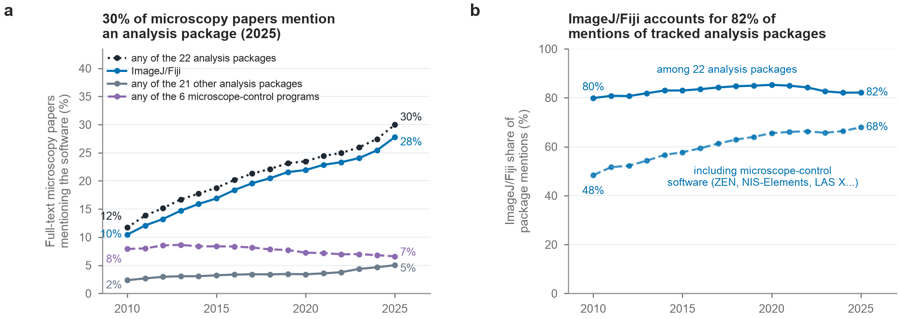

In [6]:
OUTPUT_STEM = 'Figure4__reach'
fig = figure.build_figure()
with TemporaryDirectory(prefix='figure3-notebook-') as notebook_dir, TemporaryDirectory(prefix='figure3-module-') as module_dir:
    fs.save(fig, OUTPUT_STEM, out_dir=notebook_dir)
    figure.main(out_dir=module_dir)
    notebook_png = Path(notebook_dir) / f'{OUTPUT_STEM}.png'
    module_png = Path(module_dir) / f'{OUTPUT_STEM}.png'
    notebook_image = mpimg.imread(notebook_png)
    module_image = mpimg.imread(module_png)
    assert notebook_image.shape == module_image.shape, (notebook_image.shape, module_image.shape)
    np.testing.assert_array_equal(notebook_image, module_image)
    print(f'PNG shape: {notebook_image.shape}; mean absolute pixel difference: {np.abs(notebook_image - module_image).mean():.6f}')
    from io import BytesIO
    from PIL import Image as PILImage
    preview = PILImage.open(notebook_png)
    preview.thumbnail((900, 900))
    preview_bytes = BytesIO()
    preview.save(preview_bytes, format='PNG')
    display(Image(data=preview_bytes.getvalue(), width=min(640, preview.width)))
plt.close('all')